# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Mã chính nằm trong gói `lab/` (`labels.py`, `vlm.py`, `run.py`, `viz.py`, `reward.py`, `grpo.py`).
Notebook gọi các lệnh `python -m lab.run ...` trong **tiến trình riêng** để mỗi lần chạy giải phóng GPU.
Mọi adapter/dự đoán được ghi vào Google Drive (`OUT`), và các lệnh đều **chạy lại được** sau khi mất session
(`--resume` cho train, predict bỏ qua ảnh đã làm).

## 0. Môi trường (Colab T4)

In [1]:
# Runtime → Change runtime type → T4 GPU
import os
from google.colab import drive
drive.mount('/content/drive')

REPO_URL = 'https://github.com/vietvuivui/K4-Track-4-Day10-VisionLanguageModel.git'
if not os.path.exists('/content/lab10'):
    !git clone {REPO_URL} /content/lab10
%cd /content/lab10
!git pull -q                                   # lấy bản code mới nhất nếu repo đã có sẵn
OUT = '/content/drive/MyDrive/lab10_runs'      # adapter, dự đoán, run.json (sống sót khi mất session)
os.makedirs(OUT, exist_ok=True)

Mounted at /content/drive
Cloning into '/content/lab10'...
remote: Enumerating objects: 97, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 97 (delta 12), reused 10 (delta 10), pack-reused 76 (from 1)
Receiving objects: 100% (97/97), 673.65 KiB | 61.24 MiB/s, done.
Resolving deltas: 100% (26/26), done.
/content/lab10


In [2]:
!nvidia-smi -L
!pip -q install -r requirements-colab.txt
!pip -q uninstall -y torchao   # torchao 0.10 có sẵn của Colab làm peft lỗi khi gắn LoRA vào ViT (E3)

GPU 0: NVIDIA A100-SXM4-40GB (UUID: GPU-13e21b8b-39a0-84ce-4101-5baaf1254dd6)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 123.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 66.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 73.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 55.8 MB/s eta 0:00:00


In [3]:
# Kaggle: dùng Colab Secrets (KAGGLE_API_TOKEN, dạng KGAT_...). KHÔNG viết khoá vào notebook.
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
!pip -q install -U kaggle                      # token KGAT_ cần bản kaggle CLI mới

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 12.9 MB/s eta 0:00:00


In [4]:
!python -m pytest -q            # test của đề
!python -m pytest -q lab/tests  # test của mình (nhãn, config, reward E5)

...........................s.........................................    [100%]
68 passed, 1 skipped in 0.38s
.................                                                        [100%]
17 passed in 0.07s


## 1. Dữ liệu: tải và chia split

In [5]:
if not os.path.exists('data/splits/meta.json'):
    !python scripts/prepare_data.py --kaggle

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100% 185M/185M [00:11<00:00, 17.1MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


In [6]:
# Thống kê split (câu 6) + kiểm tra không phiên quay nào nằm ở hai split
import json
from collections import Counter
from scripts.labcommon import read_jsonl, CLASSES

meta = json.load(open('data/splits/meta.json'))
print('dataset_version:', meta['dataset_version'])
splits = {s: read_jsonl(f'data/splits/{s}.jsonl') for s in ('train', 'val', 'test')}
sessions = {}
for s, rows in splits.items():
    boxes = Counter(o['label'] for r in rows for o in r['objects'])
    sess = {r['session'] for r in rows}
    sessions[s] = sess
    print(f"{s:5s} {len(rows):5d} ảnh  {len(sess):3d} phiên  " + '  '.join(f'{c}={boxes[c]}' for c in CLASSES))
for a in sessions:
    for b in sessions:
        if a < b:
            assert not sessions[a] & sessions[b], f'phiên trùng giữa {a} và {b}'
print('OK: không phiên nào xuất hiện ở hai split')

dataset_version: d10-21e4070301
train  1422 ảnh   13 phiên  pothole=1074  crack=1750  manhole=691
val     276 ảnh    2 phiên  pothole=66  crack=470  manhole=103
test    311 ảnh    3 phiên  pothole=121  crack=299  manhole=163
OK: không phiên nào xuất hiện ở hai split


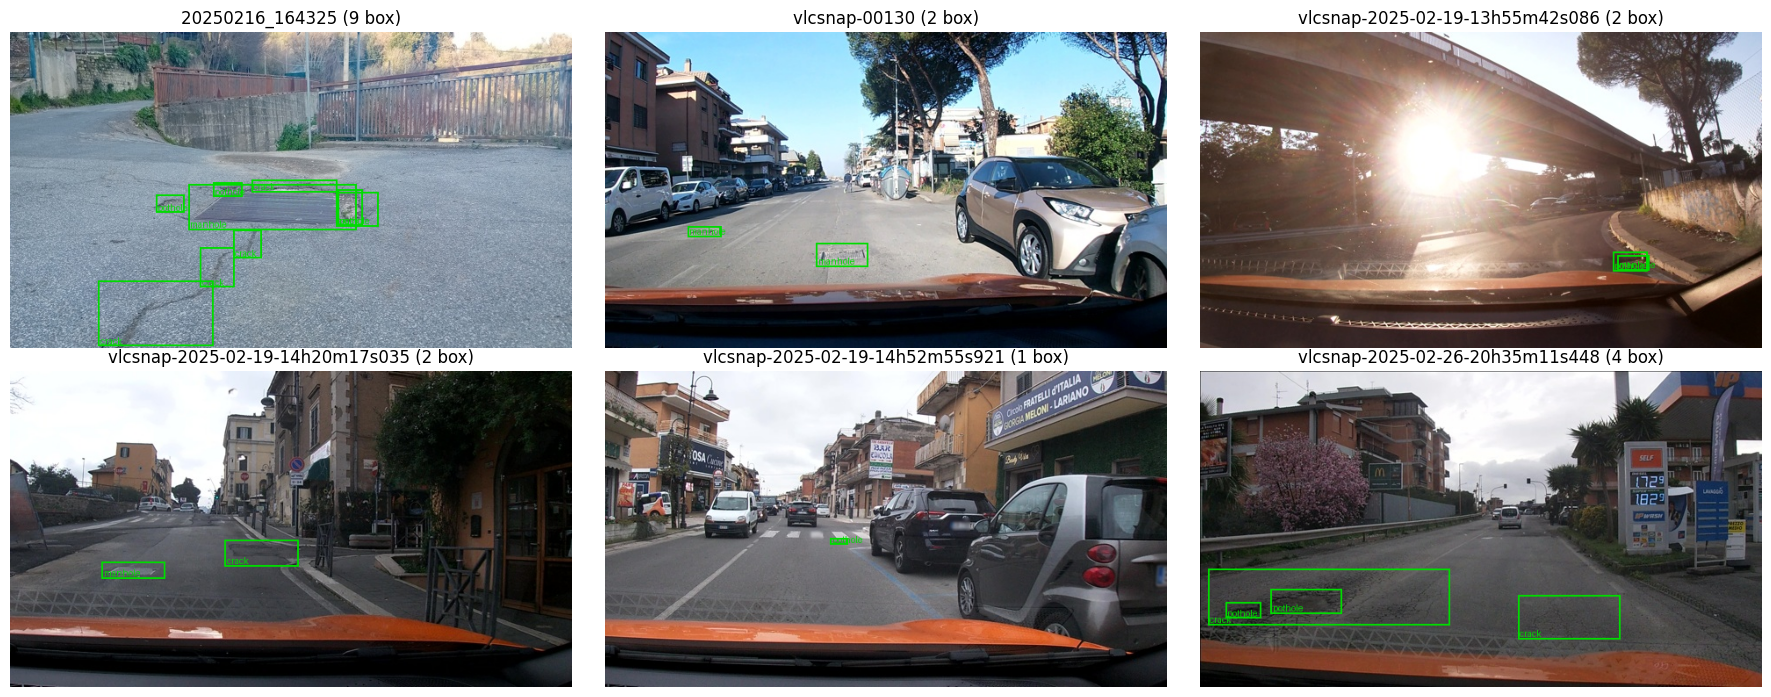

In [7]:
# Vẽ 6 ảnh train kèm box đúng
import matplotlib.pyplot as plt
from PIL import Image
from lab.viz import draw

fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for ax, r in zip(axes.flat, splits['train'][::230][:6]):
    ax.imshow(draw(Image.open('data/' + r['image_path']), r['objects']))
    ax.set_title(f"{r['image_id']} ({len(r['objects'])} box)"); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

PROMPT: Locate every road damage in this dashcam image. Classes: pothole, crack, manhole. Answer with ONLY a JSON list and no other text, in the form [{"label": "<class>", "bbox_2d": [x1, y1, x2, y2]}]. Coordinates are integers on a 0-1000 scale relative to the image width and height (0 = left/top edge, 1000 = right/bottom edge). If there is no damage, answer [].
ĐÁP ÁN: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]
sai số quy ngược lớn nhất trên toàn train: 5.00 px


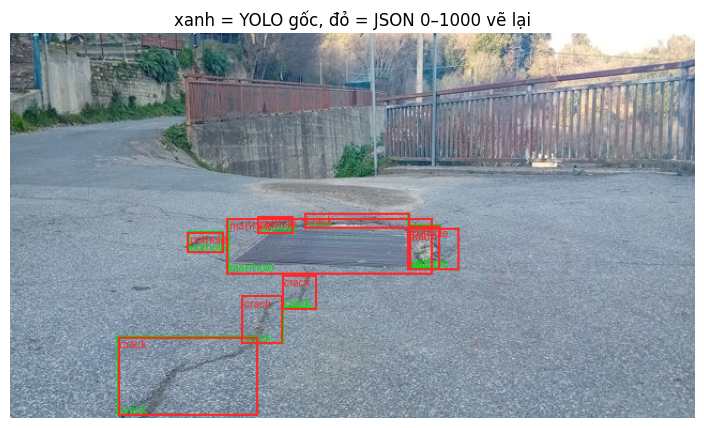

In [8]:
from lab.labels import build_prompt, objects_to_answer, objects_to_boxes, box_to_pixel, yolo_to_pixel

r = next(r for r in splits['train'] if len(r['objects']) >= 2)
print('PROMPT:', build_prompt('norm1000'))
print('ĐÁP ÁN:', objects_to_answer(r['objects']))

# Kiểm tra quy ngược: JSON 0–1000 → pixel phải trùng box gốc (sai số làm tròn ≤ 0,64 px theo x, 0,36 px theo y)
from lab.labels import yolo_to_box
err = 0.0
for row in splits['train']:
    for o in row['objects']:
        px = box_to_pixel(yolo_to_box(o['label'], o['yolo'])['bbox_2d'], 'norm1000', row['width'], row['height'])
        err = max(err, max(abs(a - c) for a, c in zip(px, yolo_to_pixel(o['yolo'], row['width'], row['height']))))
print(f'sai số quy ngược lớn nhất trên toàn train: {err:.2f} px')
pred_like = [{'label': b['label'], 'bbox': b['bbox_2d']} for b in objects_to_boxes(r['objects'])]
plt.figure(figsize=(9, 5)); plt.imshow(draw(Image.open('data/' + r['image_path']), r['objects'], pred_like))
plt.title('xanh = YOLO gốc, đỏ = JSON 0–1000 vẽ lại'); plt.axis('off'); plt.show()

## Kiến trúc Qwen3-VL-4B (câu 1)
Đếm tham số trên meta device: không tải trọng số, không tốn VRAM.

In [9]:
from lab.vlm import describe_architecture
arch = describe_architecture()
for k, v in arch['params'].items():
    print(f'{k:32s} {v/1e6:9.1f} M')
print('module LoRA khớp regex:', arch['lora_modules'], '(kỳ vọng llm=252, llm+vit=348)')
print('tie_word_embeddings:', arch['tie_word_embeddings'])

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

vit_blocks+patch_embed               306.2 M
visual.merger                         27.3 M
visual.deepstack_merger_list          81.8 M
llm (language_model)                4022.5 M
lm_head                              389.0 M
other                                  0.0 M
total                               4826.8 M
module LoRA khớp regex: {'llm': 252, 'llm+vit': 348} (kỳ vọng llm=252, llm+vit=348)
tie_word_embeddings: True


## 3. E0: zero-shot

In [10]:
!python -m lab.run predict --config configs/e0.yaml --out {OUT}/e0
!python -m lab.run score   --config configs/e0.yaml --out {OUT}/e0 --evidence report/evidence/e0.json

test: 311 ảnh, đã có 311, còn 0
/usr/bin/python3 scripts/score.py --pred /content/drive/MyDrive/lab10_runs/e0/pred_test.jsonl --split test --name E0 --out report/evidence/e0.json --coord norm1000
E0 [test] n=311 valid=0.929 P=0.132 R=0.074 F1=0.095 CI95=0.066-0.127 meanIoU=0.599 FP/img=0.91
   pothole  P=0.294 R=0.083 F1=0.129
   crack    P=0.039 R=0.027 F1=0.032
   manhole  P=0.287 R=0.153 F1=0.200


In [11]:
# Câu 2: xem output thô và phân loại lỗi của E0
from scripts.score import parse_output
e0 = read_jsonl(f'{OUT}/e0/pred_test.jsonl')
for row in e0[:5]:
    print(row['image_id'], '→', repr(row['raw'][:300]), '\n')
stats = Counter()
for row in e0:
    raw, p = row['raw'], parse_output(row['raw'])
    stats['bọc ```json'] += '```' in raw
    if p is None:
        stats['JSON hỏng / sai schema'] += 1
        continue
    stats['trả []'] += not p
    stats['nhãn ngoài 3 lớp'] += sum(b['label'] not in CLASSES for b in p)
    stats['ảnh có toạ độ > 1000'] += any(max(b['bbox']) > 1000 for b in p)
    stats['tổng box dự đoán'] += len(p)
print(dict(stats))
print('nhãn dự đoán:', Counter(b['label'] for row in e0 for b in (parse_output(row['raw']) or [])).most_common(10))

vlcsnap-00200 → '[{"label": "manhole", "bbox_2d": [759, 640, 843, 687]}]' 

vlcsnap-00201 → '[]' 

vlcsnap-00202 → '[{"label": "manhole", "bbox_2d": [309, 686, 399, 714]}]' 

vlcsnap-00203 → '[]' 

vlcsnap-00204 → '[{"label": "manhole", "bbox_2d": [257, 624, 327, 657]}]' 

{'bọc ```json': 0, 'trả []': 8, 'nhãn ngoài 3 lớp': 0, 'ảnh có toạ độ > 1000': 0, 'tổng box dự đoán': 326, 'JSON hỏng / sai schema': 22}
nhãn dự đoán: [('crack', 205), ('manhole', 87), ('pothole', 34)]


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss
Chỉ cần processor (CPU), không nạp model.

In [12]:
import torch
from transformers import AutoProcessor
from lab.vlm import make_example, collate, image_token_count
from lab.config import load_config

processor = AutoProcessor.from_pretrained('Qwen/Qwen3-VL-4B-Instruct')
cfg1 = load_config('configs/e1.yaml')
ex = make_example(processor, 'data', r, cfg1)
print({k: tuple(v.shape) for k, v in ex.items()})
print('số token ảnh:', image_token_count(processor, ex['input_ids']), '(kỳ vọng 220)')
ans_ids = ex['labels'][ex['labels'] != -100]
print('token tính loss:', len(ans_ids), '/', ex['input_ids'].shape[1])
print('giải mã phần có loss:', repr(processor.tokenizer.decode(ans_ids)))
b = collate([ex, make_example(processor, 'data', splits['train'][0], cfg1)], processor.tokenizer.pad_token_id)
print('batch:', {k: tuple(v.shape) for k, v in b.items()})
del processor

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

{'input_ids': (1, 588), 'attention_mask': (1, 588), 'mm_token_type_ids': (1, 588), 'pixel_values': (880, 1536), 'image_grid_thw': (1, 3), 'labels': (1, 588)}
số token ảnh: 220 (kỳ vọng 220)
token tính loss: 250 / 588
giải mã phần có loss: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'
batch: {'input_ids': (2, 588), 'attention_mask': (2, 588), 'mm_token_type_ids': (2, 588), 'labels': (2, 588), 'pixel_values': (1760, 1536), 'image_grid_thw': (2, 3)}


## 5. Setup LoRA / đóng băng cho E1, E2, E3
`lab/vlm.py: apply_setup()` đóng băng mọi tham số, gắn LoRA theo regex (252 module LLM; 348 khi thêm ViT),
với E2/E3 đưa `visual.merger` + `visual.deepstack_merger_list` lên fp32 và mở huấn luyện; in số module khớp
và số tham số huấn luyện (xem log của lệnh train bên dưới, và ô kiến trúc ở trên).

## 6. Vòng huấn luyện
`train()` dùng AdamW 2e-4, warmup 5% + cosine, GradScaler fp16, tích luỹ 4 × batch 2, clip 1.0,
lưu adapter + **projector riêng** (`extra_trainable.pt`) + checkpoint mỗi 100 bước, ghi `run.json`.

Mẹo: chạy E1 trước rồi gỡ lỗi trên 40 ảnh val trước khi chấm test.

In [13]:
# E1: LoRA chỉ LLM
!python -m lab.run train   --config configs/e1.yaml --out {OUT}/e1 --resume
!python -m lab.run predict --config configs/e1.yaml --out {OUT}/e1 --split val --limit 40
!python -m lab.run score   --config configs/e1.yaml --out {OUT}/e1 --split val --limit 40

/content/drive/MyDrive/lab10_runs/e1/run.json đã đủ 300 bước: bỏ qua train
val: 40 ảnh, đã có 40, còn 0
[val:40] valid=0.950 P=0.282 R=0.224 F1=0.250 FP/img=1.40


In [14]:
# Nếu val ổn (F1 E1 >> E0, valid ≈ 1): chấm test MỘT lần
!python -m lab.run predict --config configs/e1.yaml --out {OUT}/e1
!python -m lab.run score   --config configs/e1.yaml --out {OUT}/e1 --evidence report/evidence/e1.json

test: 311 ảnh, đã có 311, còn 0
/usr/bin/python3 scripts/score.py --pred /content/drive/MyDrive/lab10_runs/e1/pred_test.jsonl --split test --name E1 --out report/evidence/e1.json --coord norm1000 --meta trainable_params=33030144 --meta peak_vram_gb=6.32 --meta train_minutes=41.4
E1 [test] n=311 valid=0.990 P=0.319 R=0.262 F1=0.288 CI95=0.253-0.328 meanIoU=0.676 FP/img=1.05
   pothole  P=0.279 R=0.157 F1=0.201
   crack    P=0.207 R=0.211 F1=0.209
   manhole  P=0.670 R=0.436 F1=0.528


In [15]:
# E2: + projector (merger + deepstack_merger_list, fp32)
!python -m lab.run train   --config configs/e2.yaml --out {OUT}/e2 --resume
!python -m lab.run predict --config configs/e2.yaml --out {OUT}/e2
!python -m lab.run score   --config configs/e2.yaml --out {OUT}/e2 --evidence report/evidence/e2.json

/content/drive/MyDrive/lab10_runs/e2/run.json đã đủ 300 bước: bỏ qua train
test: 311 ảnh, đã có 311, còn 0
/usr/bin/python3 scripts/score.py --pred /content/drive/MyDrive/lab10_runs/e2/pred_test.jsonl --split test --name E2 --out report/evidence/e2.json --coord norm1000 --meta trainable_params=142135296 --meta peak_vram_gb=8.14 --meta train_minutes=26.2
E2 [test] n=311 valid=0.997 P=0.339 R=0.326 F1=0.332 CI95=0.294-0.375 meanIoU=0.671 FP/img=1.19
   pothole  P=0.197 R=0.190 F1=0.193
   crack    P=0.261 R=0.288 F1=0.274
   manhole  P=0.704 R=0.497 F1=0.583


In [16]:
# E3: + LoRA trên ViT
!python -m lab.run train   --config configs/e3.yaml --out {OUT}/e3 --resume
!python -m lab.run predict --config configs/e3.yaml --out {OUT}/e3
!python -m lab.run score   --config configs/e3.yaml --out {OUT}/e3 --evidence report/evidence/e3.json

/content/drive/MyDrive/lab10_runs/e3/run.json đã đủ 300 bước: bỏ qua train
test: 311 ảnh, đã có 311, còn 0
/usr/bin/python3 scripts/score.py --pred /content/drive/MyDrive/lab10_runs/e3/pred_test.jsonl --split test --name E3 --out report/evidence/e3.json --coord norm1000 --meta trainable_params=148426752 --meta peak_vram_gb=8.11 --meta train_minutes=22.8
E3 [test] n=311 valid=1.000 P=0.475 R=0.424 F1=0.448 CI95=0.407-0.488 meanIoU=0.702 FP/img=0.88
   pothole  P=0.419 R=0.322 F1=0.364
   crack    P=0.354 R=0.344 F1=0.349
   manhole  P=0.772 R=0.644 F1=0.702


## 7. So sánh E0–E3

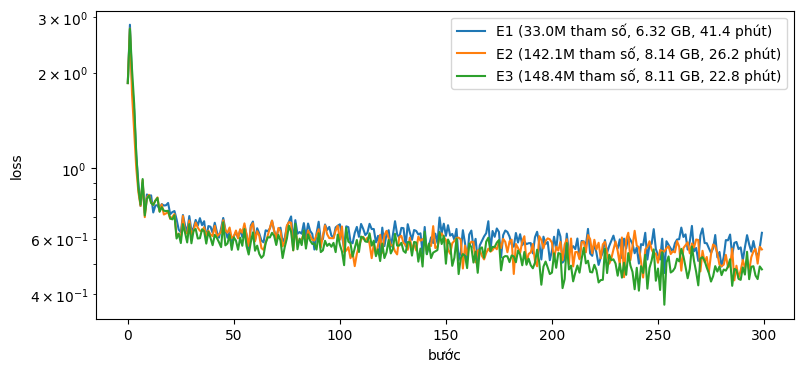

| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole | parse_valid |
|---|---|---|---|---|---|---|---|---|---|---|---|
| E0 | zero-shot | 0 | — | — | 0.095 | [0.066, 0.127] | 0.91 | 0.129 | 0.032 | 0.200 | 0.929 |
| E1 | LoRA LLM | 33,030,144 | 6.32 | 41.4 | 0.288 | [0.253, 0.328] | 1.05 | 0.201 | 0.209 | 0.528 | 0.990 |
| E2 | + projector | 142,135,296 | 8.14 | 26.2 | 0.332 | [0.294, 0.375] | 1.19 | 0.193 | 0.274 | 0.583 | 0.997 |
| E3 | + LoRA ViT | 148,426,752 | 8.11 | 22.8 | 0.448 | [0.407, 0.488] | 0.88 | 0.364 | 0.349 | 0.702 | 1.000 |


In [17]:
# Đường loss + tài nguyên (câu 7)
fig, ax = plt.subplots(figsize=(9, 4))
for e in ('e1', 'e2', 'e3'):
    p = f'{OUT}/{e}/run.json'
    if os.path.exists(p):
        run = json.load(open(p))
        ax.plot(run['losses'], label=f"{e.upper()} ({run['trainable_params']/1e6:.1f}M tham số, "
                                      f"{run['peak_vram_gb']} GB, {run['train_minutes']} phút)")
ax.set_xlabel('bước'); ax.set_ylabel('loss'); ax.set_yscale('log'); ax.legend(); plt.show()
!python -m lab.summarize

In [18]:
# Câu 3: cùng file dự đoán E1, chấm sai thang (coi output 0–1000 là pixel) → F1 thay đổi thế nào?
!python -m lab.run score --config configs/e1.yaml --out {OUT}/e1 --coord pixel --name E1-as-pixel --evidence work/e1_as_pixel.json

/usr/bin/python3 scripts/score.py --pred /content/drive/MyDrive/lab10_runs/e1/pred_test.jsonl --split test --name E1-as-pixel --out work/e1_as_pixel.json --coord pixel --meta trainable_params=33030144 --meta peak_vram_gb=6.32 --meta train_minutes=41.4
E1-as-pixel [test] n=311 valid=0.990 P=0.000 R=0.000 F1=0.000 CI95=0.000-0.000 meanIoU=0.000 FP/img=1.54
   pothole  P=0.000 R=0.000 F1=0.000
   crack    P=0.000 R=0.000 F1=0.000
   manhole  P=0.000 R=0.000 F1=0.000


## 8. E4: ablation (đổi đúng MỘT biến so với setup tốt nhất)
Mặc định: `data_size` (10% vs 100% ảnh train). Giá trị 100% chính là setup gốc nên chỉ cần **một** lần train mới.
Các lựa chọn khác để ở dạng chú thích.

In [19]:
BEST = 'e2'   # ← ĐỔI thành setup tốt nhất (e1/e2/e3) theo bảng ở trên
E4 = f'{OUT}/e4_data_size_0.1'
!python -m lab.run train   --config configs/{BEST}.yaml --set train_fraction=0.1 --set name=E4 --out {E4} --resume
!python -m lab.run predict --config configs/{BEST}.yaml --set train_fraction=0.1 --out {E4}
!python -m lab.run score   --config configs/{BEST}.yaml --set train_fraction=0.1 --out {E4} --name "E4 data_size=0.1" --evidence report/evidence/e4_data_size_0.1.json
# giá trị 1.0 = setup gốc: chấm lại đúng dự đoán test của BEST dưới tên E4
!python -m lab.run score   --config configs/{BEST}.yaml --out {OUT}/{BEST} --name "E4 data_size=1.0" --evidence report/evidence/e4_data_size_1.0.json

# --- Lựa chọn khác (chỉ chọn MỘT biến) ---
# rank: --set lora.r=4  (alpha tự = 2r)  và  --set lora.r=64  → e4_rank_4.json, e4_rank_64.json
# coord_scale: --set coord_scale=pixel (nhãn + prompt + chấm --coord pixel đều đổi theo) → e4_coord_scale_pixel.json

model.safetensors.index.json: 100% 64.7k/64.7k [00:00<00:00, 128MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/8.88G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   3% 268M/8.88G [00:02<01:00, 142MB/s, 66.8MB/s  ]
Reconstructing (incomplete total...):   9% 805M/8.88G [00:04<00:30, 266MB/s,  253MB/s  ]
Reconstructing (incomplete total...):  60% 5.35G/8.88G [00:18<00:12, 284MB/s,  424MB/s  ]
Reconstructing (incomplete total...):  86% 7.60G/8.88G [00:22<00:03, 381MB/s,  471MB/s  ]
Reconstructing (incomplete total...): 100% 8.88G/8.88G [00:23<00:00, 478MB/s,  381MB/s  ]

Fetching 2 files: 100% 2/2 [00:28<00:00, 14.07s/it]
Download complete: 100% 7.74G/7.74G [00:28<00:00, 579MB/s,  579MB/s  ]
Download complete: 100% 7.74G/7.74G [00:28<00:00, 275MB/s,  579MB/s  ]
Reconstruction complete: 100% 8.88G/8.88G [00:28<00:00, 315MB/s,  478MB/s  ]
Loading

## Ảnh minh hoạ và phân tích lỗi theo lớp (câu 9)

đã ghi 6 ảnh vào report/figures
đã ghi 2 ảnh vào report/figures
e0_sai_1.jpg


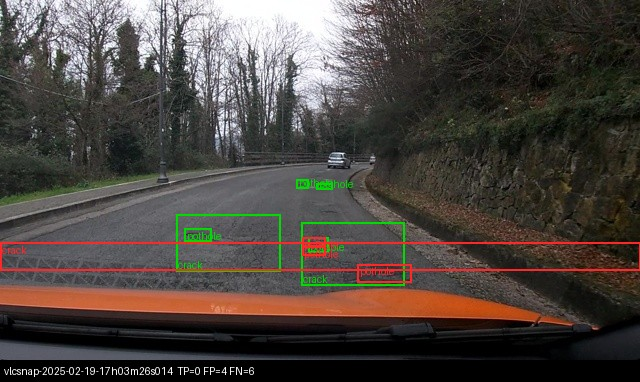

e0_sai_2.jpg


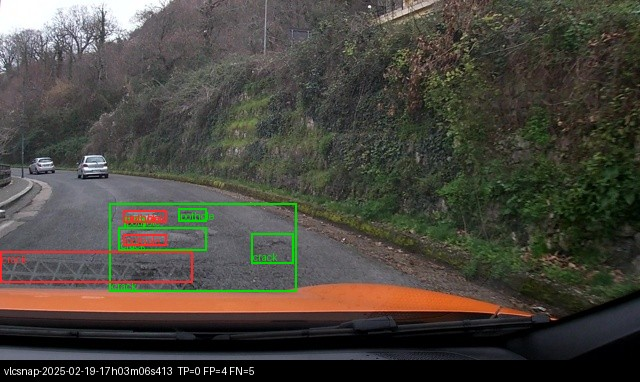

e2_dung_1.jpg


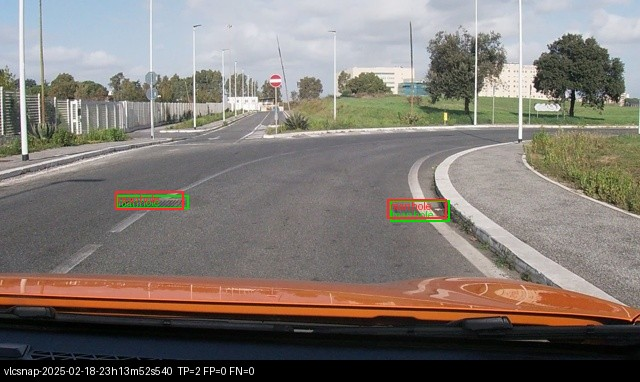

e2_dung_2.jpg


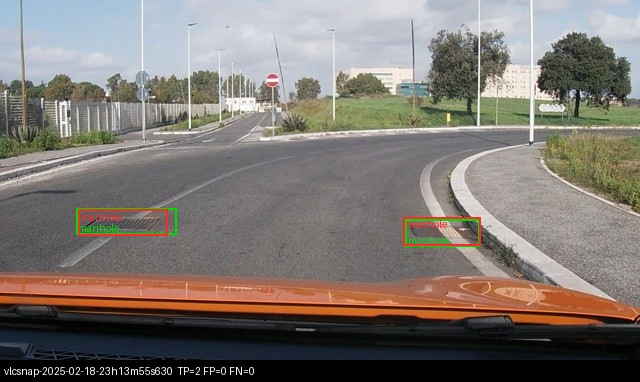

e2_dung_3.jpg


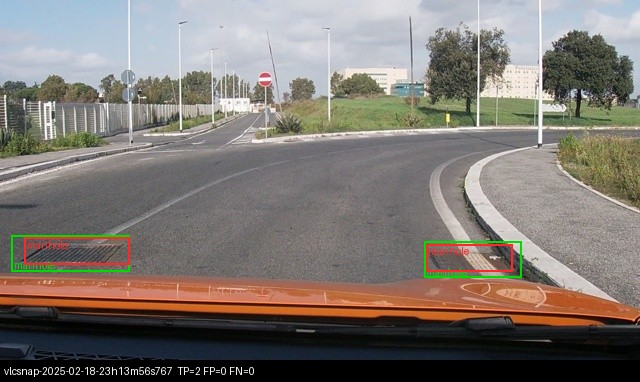

e2_sai_1.jpg


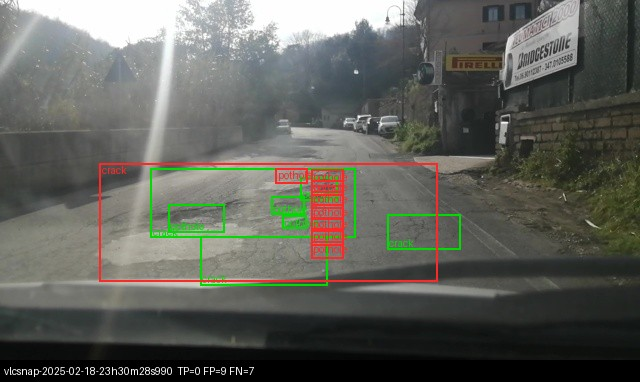

e2_sai_2.jpg


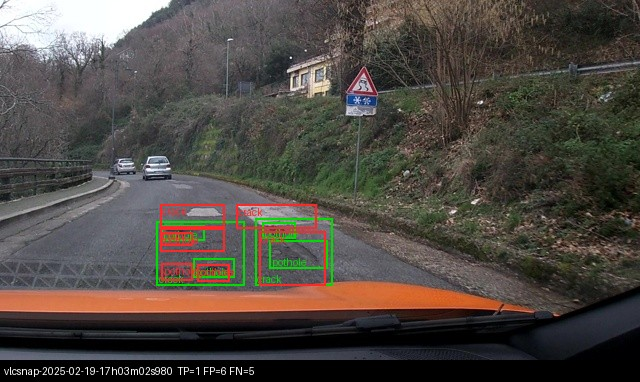

e2_sai_3.jpg


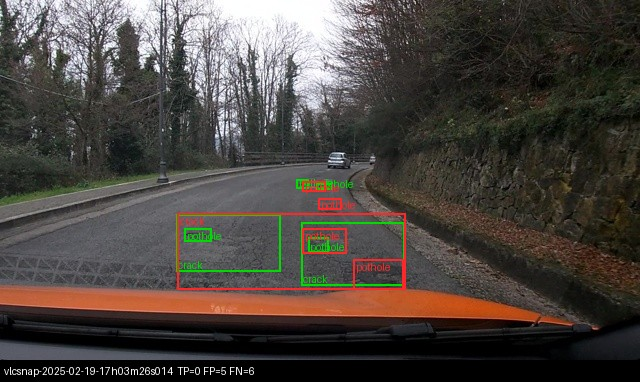

In [20]:
from lab.viz import make_figures, image_stats
make_figures(f'{OUT}/{BEST}/pred_test.jsonl', tag=BEST)          # 3 ảnh đúng + 3 ảnh sai
make_figures(f'{OUT}/e0/pred_test.jsonl', n_good=0, n_bad=2, tag='e0')
from IPython.display import Image as IPImage, display
for f in sorted(os.listdir('report/figures')):
    if f.endswith('.jpg'):
        print(f); display(IPImage('report/figures/' + f, width=640))

In [21]:
# Recall theo lớp và theo kích thước box (diện tích tương đối) trên test cho setup tốt nhất
from scripts.score import _match, _to_norm1000, iou_xyxy
from lab.reward import gt_boxes
preds = {x['image_id']: x['raw'] for x in read_jsonl(f'{OUT}/{BEST}/pred_test.jsonl')}
buckets = Counter(); hits = Counter(); areas = {c: [] for c in CLASSES}
for e in splits['test']:
    p = parse_output(preds.get(e['image_id'])) or []
    for o, g in zip(e['objects'], gt_boxes(e['objects'])):
        a = o['yolo'][2] * o['yolo'][3]
        areas[o['label']].append(a)
        size = 'nhỏ <0.5%' if a < 0.005 else ('vừa <2%' if a < 0.02 else 'lớn ≥2%')
        buckets[(o['label'], size)] += 1
        hits[(o['label'], size)] += any(q['label'] == o['label'] and iou_xyxy(g['bbox'], q['bbox']) >= 0.5 for q in p)
import statistics
for c in CLASSES:
    print(f"{c:8s} median area={statistics.median(areas[c])*100:.2f}% | " + ' | '.join(
        f"{s}: {hits[(c, s)]}/{buckets[(c, s)]}" for s in ('nhỏ <0.5%', 'vừa <2%', 'lớn ≥2%')))

pothole  median area=0.42% | nhỏ <0.5%: 13/68 | vừa <2%: 8/46 | lớn ≥2%: 2/7
crack    median area=1.98% | nhỏ <0.5%: 1/15 | vừa <2%: 31/136 | lớn ≥2%: 54/148
manhole  median area=0.67% | nhỏ <0.5%: 20/64 | vừa <2%: 60/96 | lớn ≥2%: 1/3


## Tổng hợp và kiểm tra bài nộp

In [22]:
!python -m lab.summarize --write     # ghi bảng vào REPORT.md (giữa <!-- TABLE:START/END -->)
!python scripts/check_submission.py

| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole | parse_valid |
|---|---|---|---|---|---|---|---|---|---|---|---|
| E0 | zero-shot | 0 | — | — | 0.095 | [0.066, 0.127] | 0.91 | 0.129 | 0.032 | 0.200 | 0.929 |
| E1 | LoRA LLM | 33,030,144 | 6.32 | 41.4 | 0.288 | [0.253, 0.328] | 1.05 | 0.201 | 0.209 | 0.528 | 0.990 |
| E2 | + projector | 142,135,296 | 8.14 | 26.2 | 0.332 | [0.294, 0.375] | 1.19 | 0.193 | 0.274 | 0.583 | 0.997 |
| E3 | + LoRA ViT | 148,426,752 | 8.11 | 22.8 | 0.448 | [0.407, 0.488] | 0.88 | 0.364 | 0.349 | 0.702 | 1.000 |
| E4 data_size=0.1 | data_size = 0.1 | 142,135,296 | 7.59 | 18.0 | 0.173 | [0.147, 0.202] | 2.00 | 0.099 | 0.108 | 0.431 | 0.997 |
| E4 data_size=1.0 | data_size = 1.0 | 142,135,296 | 8.14 | 26.2 | 0.332 | [0.294, 0.375] | 1.19 | 0.193 | 0.274 | 0.583 | 0.997 |
đã cập nhật bảng trong REPORT.md
[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[PASS] evidence e3
[PASS] evidence e4

## Lưu kết quả lên GitHub
Cần secret `GH_TOKEN` (GitHub token quyền `repo`). Chạy cuối mỗi phiên.

In [23]:
from google.colab import userdata
tok = userdata.get('GH_TOKEN')
!git config user.name "Nguyen Van Quoc Viet" && git config user.email "legiongk123@gmail.com"
!git add report/ REPORT.md
!git commit -m "Kết quả thí nghiệm (evidence, ảnh, bảng)" || echo "không có gì mới"
!git push https://{tok}@github.com/vietvuivui/K4-Track-4-Day10-VisionLanguageModel.git HEAD:main

SecretNotFoundError: Secret GH_TOKEN does not exist.

## 9. E5 (tuỳ chọn, +10): GRPO với reward IoU
Test reward đã có trong `lab/tests/test_lab_reward.py` (hoàn hảo, JSON hỏng, sai lớp, thừa box, rỗng, box khổng lồ).
`lab/grpo.py` viết theo API `GRPOTrainer` cho VLM; trl ghim 1.9.2, nếu tham số đổi tên hãy sửa theo docs đúng bản.

In [ ]:
!python -m pytest -q lab/tests/test_lab_reward.py
!python -m lab.grpo --base-config configs/{BEST}.yaml --base-out {OUT}/{BEST} --out {OUT}/e5
!python -m lab.run predict --config configs/{BEST}.yaml --out {OUT}/e5
!python -m lab.run score   --config configs/{BEST}.yaml --out {OUT}/e5 --name E5 --evidence report/evidence/e5.json

In [ ]:
# Reward hacking? reward theo bước + tỉ lệ output rỗng / box khổng lồ so với SFT
log = json.load(open(f'{OUT}/e5/grpo_log.json'))['log_history']
rk = next((k for k in log[0] if k.startswith('reward') and 'std' not in k), 'reward')
plt.plot([x.get(rk) for x in log if rk in x]); plt.xlabel('bước'); plt.ylabel(rk); plt.show()
for tag in (BEST, 'e5'):
    rows = [parse_output(x['raw']) for x in read_jsonl(f'{OUT}/{tag}/pred_test.jsonl')]
    ok = [p for p in rows if p is not None]
    big = sum(any((b['bbox'][2]-b['bbox'][0])*(b['bbox'][3]-b['bbox'][1]) > 250_000 for b in p) for p in ok)
    print(f"{tag}: rỗng={sum(not p for p in ok)}/{len(rows)}  box>25% ảnh={big}  "
          f"box/ảnh={sum(len(p) for p in ok)/max(len(ok),1):.2f}  JSON hỏng={len(rows)-len(ok)}")